<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<div style="text-align: center; margin-bottom: 10px;">
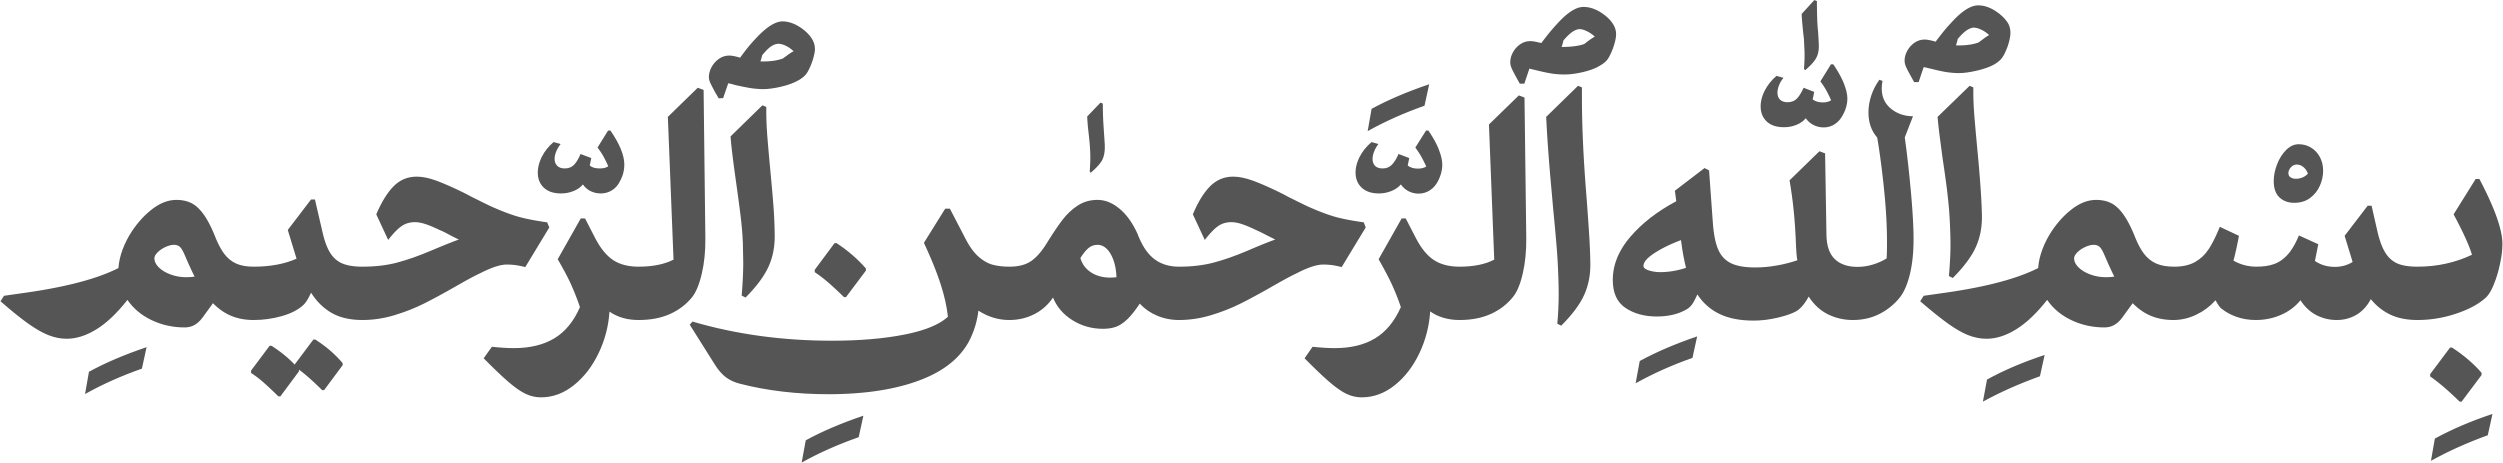
<div style="margin-top: 18px; display: flex; justify-content: center; align-items: center; gap: 30px;">
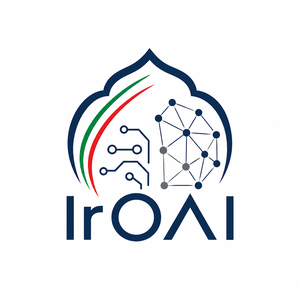
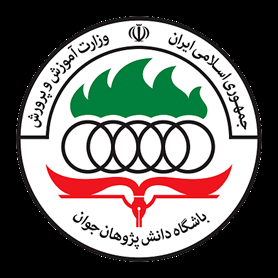
</div>
</div>
<h1 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">تمرین عملی المپیاد هوش مصنوعی — دوره دوم (۱۴۰۴-۱۴۰۵)</h1>
<h2 style="text-align: right;color: #3498db;">شبکه‌های عصبی بازگشتی: RNN، LSTM، GRU و Seq2Seq</h2>
<p style="text-align: right;"><b>موضوع:</b> پردازش داده‌های توالی، حافظه بلندمدت، گرادیان محوشونده، BPTT و ترجمه ماشینی</p>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">این یک تمرین آموزشی جامع است؛ نمره‌ای از سامانه داوری دریافت نمی‌کند. هدف، درک عمیق محاسبات، آزمایش حافظه و مقایسه معماری‌های بازگشتی است.</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h1 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">شبکه‌های عصبی بازگشتی: RNN، LSTM، GRU و Seq2Seq</h1>
<p style="text-align: right;">در این دفترچه آموزشی جامع، مسیر کامل طراحی، درک ریاضی، پیاده‌سازی و ارزیابی مدل‌های پردازش توالی را طی خواهیم کرد:</p>
<ul style="text-align: right;">
<li style="text-align: right;"><b>توالی (Sequence) چیست؟</b> چرا شبکه‌های پیش‌خور معمولی برای پردازش توالی‌ها مناسب نیستند؟</li>
<li style="text-align: right;"><b>ایده شبکه‌های عصبی بازگشتی (RNN):</b> حافظه پنهان (Hidden State) چگونه تاریخچه گذشته را نگهداری می‌کند؟</li>
<li style="text-align: right;"><b>پیاده‌سازی با <span dir="ltr"><code>nn.RNN</code></span>:</b> بررسی ابعاد تنسورهای ورودی و خروجی در PyTorch.</li>
<li style="text-align: right;"><b>مسئله حافظه (Memory Problem):</b> آزمون تجربی جمع مقادیر برای سنجش نگهداری اطلاعات در فاصله‌های طولانی.</li>
<li style="text-align: right;"><b>فرآیند BPTT و گرادیان محوشونده:</b> چرا گرادیان‌ها در طول زمان به صورت نمایی کوچک می‌شوند؟</li>
<li style="text-align: right;"><b>معماری‌های LSTM و GRU:</b> نقش دریچه‌ها (Gates) و کانال مستقیم انتقال حافظه.</li>
<li style="text-align: right;"><b>مقایسه تجربی مدل‌ها:</b> مقایسه همزمان توانایی حافظه، پایداری خطا و تعداد پارامترها در RNN، LSTM و GRU.</li>
<li style="text-align: right;"><b>ترجمه ماشینی با Seq2Seq:</b> پیاده‌سازی کامل مدل کدگذار-کدگشا مبتنی بر LSTM به همراه Teacher Forcing برای ترجمه انگلیسی به فرانسوی با دادگان واقعی NLTK.</li>
</ul>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">تمام پیاده‌سازی‌ها با استفاده از لایه‌های استاندارد PyTorch (<span dir="ltr"><code>nn.RNN</code></span>، <span dir="ltr"><code>nn.LSTM</code></span> و <span dir="ltr"><code>nn.GRU</code></span>) انجام خواهد شد.</p>
</div>


In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱ — توالی (Sequence) چیست؟</h2>
<p style="text-align: right;">بسیاری از داده‌های جهان واقعی دارای ماهیت ترتیبی و زمانی هستند. در یک توالی، ترتیب قرارگیری اعضا حامل اطلاعات معنایی بنیادین است:</p>
<ul style="text-align: right;">
<li style="text-align: right;"><b>متن (Text):</b> توالی از کلمات نظیر <span dir="ltr"><code>"I love this movie"</code></span></li>
<li style="text-align: right;"><b>سیگنال صوتی (Audio):</b> توالی از نمونه‌های سیگنال پیوسته در زمان: $x_1 \to x_2 \to x_3 \to \dots \to x_T$</li>
<li style="text-align: right;"><b>سری‌های زمانی (Time Series):</b> پیش‌بینی دما یا قیمت سهام در گام‌های متوالی</li>
<li style="text-align: right;"><b>ترجمه ماشینی (Machine Translation):</b> تبدیل یک توالی از زبان مبدأ به توالی در زبان مقصد</li>
</ul>
<p style="text-align: right;"><b>سؤال بنیادین:</b> چرا نمی‌توانیم هر مؤلفه از توالی را کاملاً مستقل از سایر مؤلفه‌ها پردازش کنیم؟</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: #3498db;">بحث کنید: اهمیت وابستگی‌های ترتیبی</h3>
<p style="text-align: right;">چرا پردازش مستقل مؤلفه‌های یک توالی (مثلاً بدون در نظر گرفتن موقعیت کلمات در یک جمله) مفهوم را دگرگون می‌کند؟ تفاوت جملات <span dir="ltr"><code>"The dog bit the man"</code></span> و <span dir="ltr"><code>"The man bit the dog"</code></span> چیست؟</p>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">پاسخ خود را در سلول Markdown زیر بنویسید (فقط برای خودتان؛ کسی آن را تصحیح نمی‌کند).</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<p style="text-align: right;"><b>پاسخ تحلیلی:</b></p>
<p style="text-align: right;">در داده‌های ترتیبی، اطلاعات در ساختار هم‌نشینی و ترتیب مؤلفه‌ها نهفته است نه صرفاً در حضور یا غیاب آن‌ها. پردازش مستقل هر عنصر به دلایل زیر شکست می‌خورد:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>نقش نحوی و معنایی وابسته به جایگاه:</b> در دو جمله <span dir="ltr"><code>"The dog bit the man"</code></span> و <span dir="ltr"><code>"The man bit the dog"</code></span>، کلمات کاملاً یکسان هستند، اما فاعل و مفعول عمل گاز گرفتن دقیقاً بر اساس ترتیب کلمات معکوس شده‌اند. پردازش بدون ترتیب نمی‌تواند فاعل و مفعول را از هم تفکیک کند.</li>
<li style="text-align: right;"><b>تغییر قطبیت و نفی معنایی:</b> در عبارتی نظیر <span dir="ltr"><code>"not bad, actually good"</code></span> کلمه <span dir="ltr"><code>not</code></span> معنای کلمه مجاور خود را معکوس می‌کند. پردازش مستقل کلمات اثر نفی را از بین می‌برد.</li>
<li style="text-align: right;"><b>وابستگی‌های ساختاری و دستوری:</b> فعل جمله بر اساس فاعل که ممکن است چندین کلمه قبل‌تر آمده باشد انتخاب می‌شود (تطابق شناسه و زمان). شبکه برای تصمیم‌گیری در گام $t$ حتماً به وضعیت گام‌های $t-1, \dots, 1$ نیاز دارد.</li>
</ol>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲ — ایده شبکه‌های عصبی بازگشتی (RNN)</h2>
<p style="text-align: right;">ایده بنیادین شبکه عصبی بازگشتی (Recurrent Neural Network) استفاده از یک بردار وضعیت پنهان ($h_t$) است که تاریخچه توالی گذشته را در خود فشرده کرده و از هر گام زمانی به گام زمانی بعدی منتقل می‌کند:</p>
<pre dir="ltr" style="background: var(--jp-cell-editor-background, #f5f5f5); padding: 10px; border-radius: 6px; font-family: monospace;">
x₁ ──→ [ RNN Cell ] ──→ h₁
              ↓
x₂ ──→ [ RNN Cell ] ──→ h₂
              ↓
x₃ ──→ [ RNN Cell ] ──→ h₃
              ↓
x₄ ──→ [ RNN Cell ] ──→ h₄
</pre>
<p style="text-align: right;">در هر گام زمانی $t$، وضعیت پنهان جدید ($h_t$) تابعی از وضعیت پنهان پیشین ($h_{t-1}$) و ورودی جاری ($x_t$) است.</p>
$$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$
$$y_t = W_{hy} h_t + b_y$$
<p style="text-align: right;"><b>نکته کلیدی (اشتراک وزن‌ها — Weight Sharing):</b> ماتریس‌های وزن $W_{xh}$ و $W_{hh}$ در تمام گام‌های زمانی $t=1, \dots, T$ یکسان و مشترک هستند.</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۳ — استفاده از لایه <span dir="ltr"><code>nn.RNN</code></span> در PyTorch</h2>
<p style="text-align: right;">در این بخش نحوه تعریف لایه بازگشتی و ارسال تنسور ورودی چندبعدی به آن را تمرین می‌کنیم.</p>
</div>


In [2]:
import torch
import torch.nn as nn

rnn = nn.RNN(input_size=10, hidden_size=32, batch_first=True)
print("RNN initialized successfully:", rnn)


RNN initialized successfully: RNN(10, 32, batch_first=True)


In [3]:
x = torch.randn(4, 7, 10)
output, hidden = rnn(x)
print("output shape:", output.shape)
print("hidden shape:", hidden.shape)


output shape: torch.Size([4, 7, 32])
hidden shape: torch.Size([1, 4, 32])


In [4]:
x_demo = torch.randn(4, 7, 10)
output_demo, hidden_demo = rnn(x_demo)

print("Demo batch size:     ", output_demo.shape[0])
print("Demo sequence length:", output_demo.shape[1])
print("Demo hidden size:    ", output_demo.shape[2])
print("Verification: last timestep matches hidden state:")
print("Are equal:", torch.allclose(output_demo[:, -1, :], hidden_demo.squeeze(0), atol=1e-6))


Demo batch size:      4
Demo sequence length: 7
Demo hidden size:     32
Verification: last timestep matches hidden state:
Are equal: True


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: #3498db;">بررسی ابعاد (Shapes) در <span dir="ltr"><code>nn.RNN</code></span></h3>
<p style="text-align: right;">هنگامی که پارامتر <span dir="ltr"><code>batch_first=True</code></span> باشد، ابعاد تنسورها به شکل زیر خواهد بود:</p>
$$X \in \mathbb{R}^{B \times T \times D}$$
$$output \in \mathbb{R}^{B \times T \times H}$$
$$hidden \in \mathbb{R}^{L \times B \times H}$$
<p style="text-align: right;"><b>تفاوت بنیادی خروجی‌های <span dir="ltr"><code>output</code></span> و <span dir="ltr"><code>hidden</code></span>:</b></p>
<ul style="text-align: right;">
<li style="text-align: right;"><span dir="ltr"><code>output</code></span> شامل وضعیت پنهان آخرین لایه برای <b>تمام گام‌های زمانی</b> ($t=1, \dots, T$) است.</li>
<li style="text-align: right;"><span dir="ltr"><code>hidden</code></span> شامل وضعیت پنهان تمام لایه‌ها برای <b>تنها آخرین گام زمانی</b> ($t=T$) است.</li>
</ul>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۴ — مسئله حافظه (The Adding / Memory Problem)</h2>
<p style="text-align: right;">برای آزمودن ظرفیت نگهداری حافظه بلندمدت در شبکه‌های بازگشتی، یک مسئله کلاسیک به نام <b>مسئله جمع حافظه</b> طراحی می‌کنیم:</p>
<pre dir="ltr" style="background: var(--jp-cell-editor-background, #f5f5f5); padding: 10px; border-radius: 6px; font-family: monospace;">
ورودی:   [ 7,  0,  0,  0,  0,  0,  0,  0,  0,  3 ]
هدف:     y = 7 + 3 = 10
</pre>
<p style="text-align: right;">آیا RNN ساده می‌تواند عدد گام اول را در وضعیت پنهان خود حفظ کند تا زمانی که به گام آخر برسد؟</p>
</div>


In [5]:
def generate_memory_dataset(n_samples, seq_len):
    x = torch.zeros(n_samples, seq_len)
    x[:, 0] = torch.randint(0, 10, (n_samples,)).float()
    x[:, -1] = torch.randint(0, 10, (n_samples,)).float()
    y = x[:, 0] + x[:, -1]
    return x, y


In [6]:
sequence_lengths = [5, 10, 25, 50, 100, 200]
for seq_len in sequence_lengths:
    x, y = generate_memory_dataset(n_samples=1000, seq_len=seq_len)
    print(f"seq_len: {seq_len:3d} | x shape: {tuple(x.shape)} | y shape: {tuple(y.shape)}")


seq_len:   5 | x shape: (1000, 5) | y shape: (1000,)
seq_len:  10 | x shape: (1000, 10) | y shape: (1000,)
seq_len:  25 | x shape: (1000, 25) | y shape: (1000,)
seq_len:  50 | x shape: (1000, 50) | y shape: (1000,)
seq_len: 100 | x shape: (1000, 100) | y shape: (1000,)
seq_len: 200 | x shape: (1000, 200) | y shape: (1000,)


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۵ — ساخت مدل بازگشتی MemoryRNN</h2>
<p style="text-align: right;">یک مدل پایه‌ای مبتنی بر <span dir="ltr"><code>nn.RNN</code></span> پیاده‌سازی می‌کنیم که وضعیت پنهان گام نهایی را از طریق یک لایه تمام‌متصل خطی به پیش‌بینی حاصل‌جمع تبدیل می‌کند.</p>
</div>


In [7]:
class MemoryRNN(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, hidden = self.rnn(x)
        return self.fc(hidden[-1])


In [8]:
model = MemoryRNN(hidden_size=32).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
print("Model, criterion, and optimizer created successfully.")


Model, criterion, and optimizer created successfully.


In [9]:
x_sample, y_sample = generate_memory_dataset(n_samples=128, seq_len=10)
x_sample = x_sample.unsqueeze(-1).to(device)
y_sample = y_sample.unsqueeze(-1).to(device)

optimizer.zero_grad()
pred = model(x_sample)
loss = criterion(pred, y_sample)
loss.backward()
optimizer.step()
print(f"Single step loss: {loss.item():.4f}")

def train_model(model, x, y, epochs=18, lr=3e-3, batch_size=64):
    model = model.to(device)
    crit = nn.MSELoss()
    opt = optim.Adam(model.parameters(), lr=lr)
    dataset = torch.utils.data.TensorDataset(x, y.unsqueeze(-1) if y.ndim == 1 else y)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    losses = []
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            p = model(bx)
            l = crit(p, by)
            l.backward()
            opt.step()
            epoch_loss += l.item() * len(bx)
        losses.append(epoch_loss / len(dataset))
    return losses[-1]


Single step loss: 101.9319


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۶ — خط سیر آموزش و گرادیان‌ها</h2>
<p style="text-align: right;">جریان آموزش در شبکه‌های بازگشتی از چرخه استاندارد انتشار رو به جلو، محاسبه زیان و بازگشت خطا در طول زمان پیروی می‌کند:</p>
$$\theta \leftarrow \theta - \eta \nabla_\theta L$$
</div>


In [10]:
print("Parameter gradient norms:")
for name, param in model.named_parameters():
    if param.grad is not None:
        print(f"  {name:20s} | grad norm: {param.grad.norm().item():.6f}")


Parameter gradient norms:
  rnn.weight_ih_l0     | grad norm: 41.427299
  rnn.weight_hh_l0     | grad norm: 11.322706
  rnn.bias_ih_l0       | grad norm: 10.480393
  rnn.bias_hh_l0       | grad norm: 10.480393
  fc.weight            | grad norm: 47.824192
  fc.bias              | grad norm: 18.522141


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۷ — انتشار بازگشتی در طول زمان (BPTT)</h2>
<p style="text-align: right;">هنگامی که یک RNN در طول زمان باز (Unroll) می‌شود، فرآیند مشتق‌گیری زنجیره‌ای به سمت گام‌های نخستین زمان <b>Backpropagation Through Time (BPTT)</b> نام دارد:</p>
$$\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T} \frac{\partial h_k}{\partial h_{k-1}} = \prod_{k=t+1}^{T} \text{diag}(1 - \tanh^2(\dots)) W_{hh}^T$$
<p style="text-align: right;">اگر مقادیر ماتریس کمتر از ۱ باشد، این زنجیره ضرب مکرر سیگنال گرادیان را به صورت نمایی به صفر میل می‌دهد (Vanishing Gradient).</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۸ — مشاهده گرادیان محوشونده (Vanishing Gradient)</h2>
<p style="text-align: right;">گرادیان تابع زیان را نسبت به ورودی در تک‌تک گام‌های زمانی ($t=0, \dots, T-1$) استخراج و رسم می‌کنیم تا میرایی نمایی سیگنال گرادیان را مستقیماً مشاهده نماییم.</p>
</div>


In [11]:
seq_len_obs = 30
x_obs, y_obs = generate_memory_dataset(n_samples=64, seq_len=seq_len_obs)
x_obs = x_obs.unsqueeze(-1).to(device)
y_obs = y_obs.unsqueeze(-1).to(device)

x_obs = x_obs.clone().detach().requires_grad_(True)
pred_obs = model(x_obs)
loss_obs = criterion(pred_obs, y_obs)
loss_obs.backward()

print("Input gradient tensor shape:", x_obs.grad.shape)


Input gradient tensor shape: torch.Size([64, 30, 1])


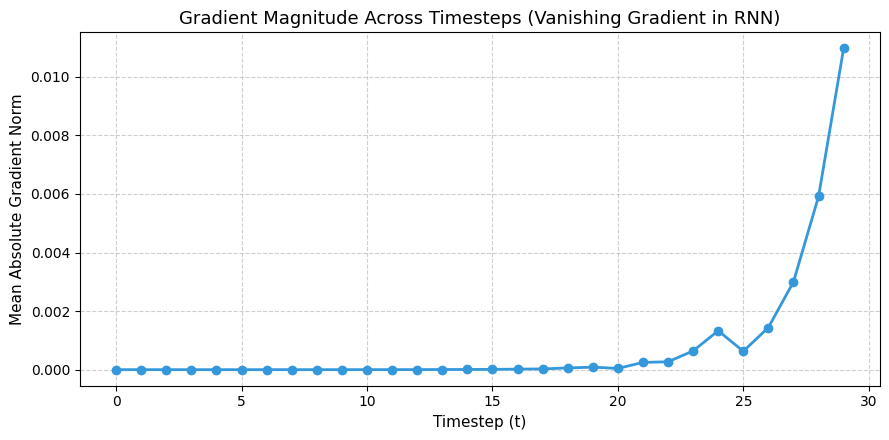

In [12]:
grad_norms_per_step = x_obs.grad.abs().mean(dim=0).squeeze(-1).cpu().numpy()

plt.figure(figsize=(9, 4.5))
plt.plot(range(seq_len_obs), grad_norms_per_step, marker='o', color='#3498db', linewidth=2)
plt.title("Gradient Magnitude Across Timesteps (Vanishing Gradient in RNN)", fontsize=13)
plt.xlabel("Timestep (t)", fontsize=11)
plt.ylabel("Mean Absolute Gradient Norm", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: #3498db;">بحث و تحلیل: محو شدن گرادیان در طول زمان</h3>
<p style="text-align: right;">در نمودار بالا چه رفتاری مشاهده می‌کنید؟ چرا با حرکت از گام‌های انتهایی (نزدیک به تابع زیان) به سمت گام‌های ابتدایی، اندازه گرادیان به شدت افت می‌کند؟</p>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">پاسخ خود را در سلول Markdown زیر بنویسید (فقط برای خودتان؛ کسی آن را تصحیح نمی‌کند).</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<p style="text-align: right;"><b>پاسخ تحلیلی:</b></p>
<p style="text-align: right;">در نمودار به وضوح دیده می‌شود که اندازه گرادیان ورودی در گام‌های نزدیک به خروجی ($t \approx 29$) دارای مقادیر قابل توجه است، اما با حرکت به سمت گام‌های اولیه ($t \to 0$)، مقدار گرادیان به سرعت افت کرده و عملاً به صفر می‌رسد. دلایل این رفتار:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>ضرب متوالی ژاکوبین‌ها:</b> برای انتقال پیام خطا از گام $T$ به گام $0$، مشتق باید در $T$ ماتریس ژاکوبین $\frac{\partial h_k}{\partial h_{k-1}}$ ضرب شود. چون مشتق $\tanh$ همواره بین ۰ و ۱ است، این ضرب مکرر سیگنال گرادیان را میرایی می‌کند.</li>
<li style="text-align: right;"><b>کوری نسبت به گذشته دور:</b> به دلیل صفر شدن گرادیان در گام‌های اولیه، مشتقات مربوط به داده‌های گذشته عملاً بدون تغییر می‌مانند؛ بنابراین شبکه هرگز نمی‌تواند یاد بگیرد که ورودی گام اول ($x_0$) برای پیش‌بینی نهایی ضروری است.</li>
</ol>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۹ — آزمایش اصلی حافظه در RNN</h2>
<p style="text-align: right;">عملکرد شبکه RNN ساده را در حفظ اطلاعات در طول‌های توالی مختلف ($T=5, 10, 25, 50, 100, 200$) می‌سنجیم.</p>
</div>


In [13]:
sequence_lengths = [5, 10, 25, 50, 100, 200]
memory_datasets = {}

for seq_len in sequence_lengths:
    x_mem, y_mem = generate_memory_dataset(n_samples=3000, seq_len=seq_len)
    memory_datasets[seq_len] = (x_mem.unsqueeze(-1), y_mem)

print("Memory datasets prepared for sequence lengths:", sequence_lengths)


Memory datasets prepared for sequence lengths: [5, 10, 25, 50, 100, 200]


In [14]:
rnn_memory_results = {}
for seq_len, (x_data, y_data) in memory_datasets.items():
    torch.manual_seed(100 + seq_len)
    model_rnn = MemoryRNN(hidden_size=32).to(device)
    final_loss = train_model(model_rnn, x_data, y_data, epochs=18, lr=3e-3)
    rnn_memory_results[seq_len] = final_loss
    print(f"RNN Sequence Length: {seq_len:3d} | Final MSE Loss: {final_loss:.4f}")


RNN Sequence Length:   5 | Final MSE Loss: 0.0306


RNN Sequence Length:  10 | Final MSE Loss: 8.2393


RNN Sequence Length:  25 | Final MSE Loss: 8.5010


RNN Sequence Length:  50 | Final MSE Loss: 8.1770


RNN Sequence Length: 100 | Final MSE Loss: 8.3386


RNN Sequence Length: 200 | Final MSE Loss: 8.3221


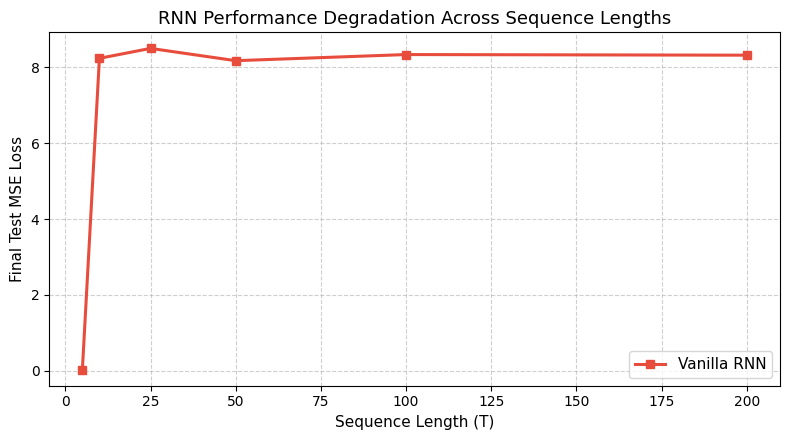

In [15]:
plt.figure(figsize=(8, 4.5))
plt.plot(list(rnn_memory_results.keys()), list(rnn_memory_results.values()), 
         marker='s', color='#e74c3c', linewidth=2.2, label='Vanilla RNN')
plt.title("RNN Performance Degradation Across Sequence Lengths", fontsize=13)
plt.xlabel("Sequence Length (T)", fontsize=11)
plt.ylabel("Final Test MSE Loss", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۰ — ایده معماری LSTM: بزرگراه گرادیان</h2>
<p style="text-align: right;">مسئله بنیادین RNN این بود که گرادیان در مسیر بازگشت خود مجبور بود از تبدیلات غیرخطی متوالی عبور کند. معماری Long Short-Term Memory با معرفی <b>Cell State</b> ($C_t$) یک بزرگراه خطی برای انتقال بدون تضعیف حافظه و گرادیان ایجاد می‌کند.</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۱ — فرمول‌های ریاضی و دریچه‌های LSTM</h2>
<p style="text-align: right;">یک سلول LSTM از سه دریچه کنترل‌کننده تشکیل شده است:</p>
$$f_t = \sigma(W_f [h_{t-1}, x_t] + b_f) \quad \text{(Forget Gate)}$$
$$i_t = \sigma(W_i [h_{t-1}, x_t] + b_i) \quad \text{(Input Gate)}$$
$$\tilde{C}_t = \tanh(W_c [h_{t-1}, x_t] + b_c)$$
$$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t \quad \text{(Cell State)}$$
$$o_t = \sigma(W_o [h_{t-1}, x_t] + b_o) \quad \text{(Output Gate)}$$
$$h_t = o_t \odot \tanh(C_t)$$
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۲ — چرا LSTM گرادیان را حفظ می‌کند؟</h2>
<p style="text-align: right;">مشتق وضعیت سلولی در گام $t$ نسبت به گام قبلی $t-1$ به صورت مستقیم برابر با دریچه فراموشی است:</p>
$$\frac{\partial C_t}{\partial C_{t-1}} = f_t \implies \frac{\partial C_T}{\partial C_t} = \prod_{k=t+1}^{T} f_k \approx 1$$
<p style="text-align: right;">اگر دریچه‌های فراموشی باز باشند ($f_t \approx 1$)، گرادیان بدون تضعیف نمایی در طول صدها گام زمانی به عقب منتقل می‌شود.</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۳ — معماری کم‌حجم‌تر: GRU (Gated Recurrent Unit)</h2>
<p style="text-align: right;">معماری Gated Recurrent Unit (GRU) وضعیت پنهان و سلولی را ادغام کرده و با دو دریچه، حافظه طولانی را با محاسبات کمتری فراهم می‌سازد:</p>
$$z_t = \sigma(W_z x_t + U_z h_{t-1}) \quad \text{(Update Gate)}$$
$$r_t = \sigma(W_r x_t + U_r h_{t-1}) \quad \text{(Reset Gate)}$$
$$\tilde{h}_t = \tanh(W_h x_t + U_h (r_t \odot h_{t-1}))$$
$$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$$
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۴ — مقایسه تجربی RNN، LSTM و GRU</h2>
<p style="text-align: right;">یک کلاس واحد <span dir="ltr"><code>SequenceModel</code></span> برای پشتیبانی از هر سه معماری پیاده‌سازی کرده و عملکرد آن‌ها را در طول‌های مختلف توالی مقایسه می‌کنیم.</p>
</div>


In [16]:
rnn_layer = nn.RNN(input_size=1, hidden_size=32, batch_first=True)
lstm_layer = nn.LSTM(input_size=1, hidden_size=32, batch_first=True)
gru_layer = nn.GRU(input_size=1, hidden_size=32, batch_first=True)
print("All three recurrent layers instantiated successfully.")


All three recurrent layers instantiated successfully.


In [17]:
class SequenceModel(nn.Module):
    def __init__(self, architecture, input_size=1, hidden_size=32, output_size=1):
        super().__init__()
        self.architecture = architecture
        if architecture == "RNN":
            self.recurrent = nn.RNN(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        elif architecture == "LSTM":
            self.recurrent = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
            for name, param in self.recurrent.named_parameters():
                if 'bias' in name:
                    param.data[hidden_size:2*hidden_size].fill_(2.0)
        elif architecture == "GRU":
            self.recurrent = nn.GRU(input_size=input_size, hidden_size=hidden_size, batch_first=True)
            for name, param in self.recurrent.named_parameters():
                if 'bias' in name:
                    param.data[hidden_size:2*hidden_size].fill_(2.0)
        else:
            raise ValueError(f"Unknown architecture: {architecture}")
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        if self.architecture == "LSTM":
            output, (hidden, cell) = self.recurrent(x)
        else:
            output, hidden = self.recurrent(x)
        return self.fc(hidden[-1])


In [18]:
benchmark_results = {"RNN": {}, "LSTM": {}, "GRU": {}}

for arch in ["RNN", "LSTM", "GRU"]:
    print(f"Training {arch} across sequence lengths...")
    for seq_len, (x_d, y_d) in memory_datasets.items():
        torch.manual_seed(100 + seq_len)
        m = SequenceModel(arch, input_size=1, hidden_size=32, output_size=1).to(device)
        loss_val = train_model(m, x_d, y_d, epochs=18, lr=3e-3)
        benchmark_results[arch][seq_len] = loss_val
        print(f"  {arch:4s} | seq_len: {seq_len:3d} | MSE Loss: {loss_val:.4f}")


Training RNN across sequence lengths...


  RNN  | seq_len:   5 | MSE Loss: 0.0306


  RNN  | seq_len:  10 | MSE Loss: 8.2393


  RNN  | seq_len:  25 | MSE Loss: 8.5010


  RNN  | seq_len:  50 | MSE Loss: 8.1770


...

  GRU  | seq_len:  10 | MSE Loss: 0.0369


  GRU  | seq_len:  25 | MSE Loss: 0.0297


  GRU  | seq_len:  50 | MSE Loss: 0.0483


  GRU  | seq_len: 100 | MSE Loss: 0.0327


  GRU  | seq_len: 200 | MSE Loss: 0.0478


Performance Comparison Table (MSE Loss):
                      RNN      LSTM       GRU
Sequence Length                              
5                0.030611  0.032593  0.082514
10               8.239330  0.035479  0.036868
25               8.501001  0.062274  0.029697
50               8.177034  0.045332  0.048268
100              8.338650  8.363671  0.032656
200              8.322133  8.269362  0.047753


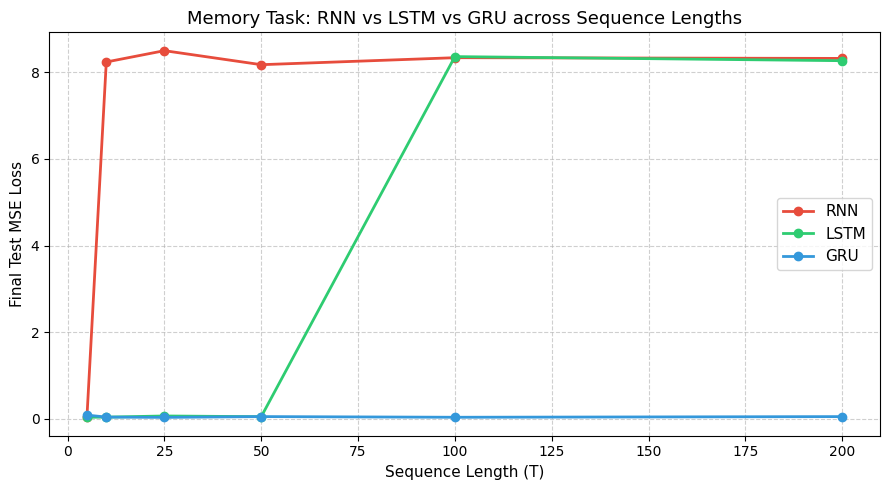

In [19]:
import pandas as pd

results_df = pd.DataFrame(benchmark_results)
results_df.index.name = "Sequence Length"
print("Performance Comparison Table (MSE Loss):")
print(results_df.to_string())

plt.figure(figsize=(9, 5))
for arch, color in zip(["RNN", "LSTM", "GRU"], ['#e74c3c', '#2ecc71', '#3498db']):
    plt.plot(list(benchmark_results[arch].keys()), list(benchmark_results[arch].values()),
             marker='o', label=arch, color=color, linewidth=2)
plt.title("Memory Task: RNN vs LSTM vs GRU across Sequence Lengths", fontsize=13)
plt.xlabel("Sequence Length (T)", fontsize=11)
plt.ylabel("Final Test MSE Loss", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: #3498db;">تحلیل و پرسش‌های مفهومی مقایسه مدل‌ها</h3>
<ul style="text-align: right;">
<li style="text-align: right;">آیا مدل‌های LSTM و GRU برتری معناداری نسبت به RNN نشان دادند؟</li>
<li style="text-align: right;">از چه طول توالی ($T$) به بعد، تفاوت کارایی مدل‌ها آشکار شد؟</li>
<li style="text-align: right;">آیا LSTM و GRU مشکل گرادیان محوشونده را کاملاً و به طور ۱۰۰٪ حذف می‌کنند؟</li>
</ul>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">پاسخ خود را در سلول Markdown زیر بنویسید (فقط برای خودتان؛ کسی آن را تصحیح نمی‌کند).</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<p style="text-align: right;"><b>پاسخ تحلیلی:</b></p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>برتری LSTM و GRU:</b> بله؛ در طول‌های کوتاه ($T=5$) هر سه مدل خطا را پایین نگه می‌دارند، اما به محض افزایش طول به $T=10$ و بالاتر، خطای RNN ساده به شدت افزایش می‌یابد ($pprox 8.2$)، در حالی که LSTM و GRU خطا را در نزدیکی صفر حفظ می‌کنند.</li>
<li style="text-align: right;"><b>مرز تمایز:</b> در حدود $T \ge 10$ شکست RNN آغاز می‌شود و در طول‌های بزرگ‌تر مدل RNN ساده کاملاً اطلاعات گام اول را فراموش می‌کند.</li>
<li style="text-align: right;"><b>عدم حذف کامل:</b> خیر؛ اگرچه LSTM و GRU مشکل گرادیان محوشونده را به شدت کاهش می‌دهند، اما در فواصل بسیار بلند، افت تدریجی عملکرد مشاهده می‌شود که انگیزه معرفی مکانیزم‌های توجه (Attention) گردید.</li>
</ol>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۵ — مقایسه تعداد پارامترها (Parameter Count)</h2>
<p style="text-align: right;">تعداد کل پارامترهای آموزش‌پذیر را در معماری‌های مختلف با ابعاد یکسان مقایسه می‌کنیم.</p>
</div>


In [20]:
def count_parameters(model):
    """Counts the total number of trainable parameters in a PyTorch model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [21]:
test_models = {
    "RNN": SequenceModel("RNN", input_size=1, hidden_size=32),
    "GRU": SequenceModel("GRU", input_size=1, hidden_size=32),
    "LSTM": SequenceModel("LSTM", input_size=1, hidden_size=32)
}

print("Parameter Count Comparison (input_size=1, hidden_size=32):")
for name, m in test_models.items():
    print(f"  {name:6s}: {count_parameters(m):5d} parameters")


Parameter Count Comparison (input_size=1, hidden_size=32):
  RNN   :  1153 parameters
  GRU   :  3393 parameters
  LSTM  :  4513 parameters


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: #3498db;">تحلیل مقایسه‌ای تعداد پارامترها</h3>
<p style="text-align: right;">ترتیب تعداد پارامترها همواره به صورت زیر است:</p>
<pre dir="ltr" style="background: var(--jp-cell-editor-background, #f5f5f5); padding: 10px; border-radius: 6px; font-family: monospace;">
RNN (1 set of weights)  &lt;  GRU (3 sets of weights)  &lt;  LSTM (4 sets of weights)
</pre>
<ul style="text-align: right;">
<li style="text-align: right;"><b>RNN:</b> تنها یک تبدیل خطی اصلی دارد ($W_{xh}, W_{hh}, b_h$).</li>
<li style="text-align: right;"><b>GRU:</b> دارای ۳ تبدیل خطی مجزا است (دریچه‌های Update, Reset و Candidate)؛ تقریباً ۳ برابر RNN.</li>
<li style="text-align: right;"><b>LSTM:</b> دارای ۴ تبدیل خطی مجزا است (دریچه‌های Forget, Input, Output و Candidate)؛ تقریباً ۴ برابر RNN.</li>
</ul>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">بخش ۱۶ — مدل‌های دنباله‌به‌دنباله (Sequence-to-Sequence Translation)</h2>
<p style="text-align: right;">اکنون از یک مسئله مصنوعی ریاضی به یک مسئله واقعی در پردازش زبان طبیعی (NLP) وارد می‌شویم: <b>ترجمه ماشینی انگلیسی به فرانسوی</b>.</p>
<pre dir="ltr" style="background: var(--jp-cell-editor-background, #f5f5f5); padding: 10px; border-radius: 6px; font-family: monospace;">
English: "Resumption of the session"
              ↓
      [ LSTM Encoder ]
              ↓  Context (h, c)
      [ LSTM Decoder ]
              ↓
French:  "Reprise de la session"
</pre>
<p style="text-align: right;">در این معماری کدگذار (Encoder) کل جمله انگلیسی را خوانده و خلاصه آن را در وضعیت‌های $(h_T, c_T)$ ذخیره می‌کند؛ سپس کدگشا (Decoder) جمله فرانسوی را گام‌به‌گام تولید می‌کند.</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۷ — بارگذاری دادگان موازی با NLTK</h2>
<p style="text-align: right;">از پیکره موازی <span dir="ltr"><code>comtrans</code></span> در کتابخانه NLTK برای استخراج جفت‌جملات ترجمه‌شده انگلیسی-فرانسوی استفاده می‌کنیم.</p>
</div>


In [22]:
import nltk
nltk.download("comtrans", quiet=True)
print("NLTK comtrans package is ready.")


NLTK comtrans package is ready.


In [23]:
from nltk.corpus import comtrans

data = comtrans.aligned_sents("alignment-en-fr.txt")
print(f"Total aligned sentences in comtrans: {len(data)}")


Total aligned sentences in comtrans: 33334


In [24]:
sample_demo = data[0]
print("English Sentence (sample 0):")
print(" ".join(sample_demo.words))
print()
print("French Sentence (sample 0):")
print(" ".join(sample_demo.mots))


English Sentence (sample 0):
Resumption of the session

French Sentence (sample 0):
Reprise de la session


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۸ — بررسی آماری دادگان و توزیع طول جملات</h2>
<p style="text-align: right;">بررسی نمونه‌های اولیه و تحلیل طول جملات انگلیسی و فرانسوی جهت طراحی لایه Padding مناسب.</p>
</div>


In [25]:
for i in range(5):
    en_s = " ".join(data[i].words)
    fr_s = " ".join(data[i].mots)
    print(f"Sample #{i+1}:")
    print(f"  EN: {en_s}")
    print(f"  FR: {fr_s}\n")


Sample #1:
  EN: Resumption of the session
  FR: Reprise de la session

Sample #2:
  EN: I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999 , and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period .
  FR: Je déclare reprise la session du Parlement européen qui avait été interrompue le vendredi 17 décembre dernier et je vous renouvelle tous mes vux en espérant que vous avez passé de bonnes vacances .

Sample #3:
  EN: You have requested a debate on this subject in the course of the next few days , during this part-session .
  FR: Vous avez souhaité un débat à ce sujet dans les prochains jours , au cours de cette période de session .

Sample #4:
  EN: Please rise , then , for this minute ' s silence .
  FR: Je vous invite à vous lever pour cette minute de silence .

Sample #5:
  EN: ( The House rose and observed a minute ' s silence )
  FR: ( Le Parlement , debout , observe une minute de s

In [26]:
en_lengths = [len(s.words) for s in data]
fr_lengths = [len(s.mots) for s in data]

print(f"English sentences: min={min(en_lengths):2d}, max={max(en_lengths):3d}, avg={sum(en_lengths)/len(en_lengths):.2f}")
print(f"French sentences:  min={min(fr_lengths):2d}, max={max(fr_lengths):3d}, avg={sum(fr_lengths)/len(fr_lengths):.2f}")


English sentences: min= 1, max= 40, avg=20.18
French sentences:  min= 1, max= 40, avg=22.03


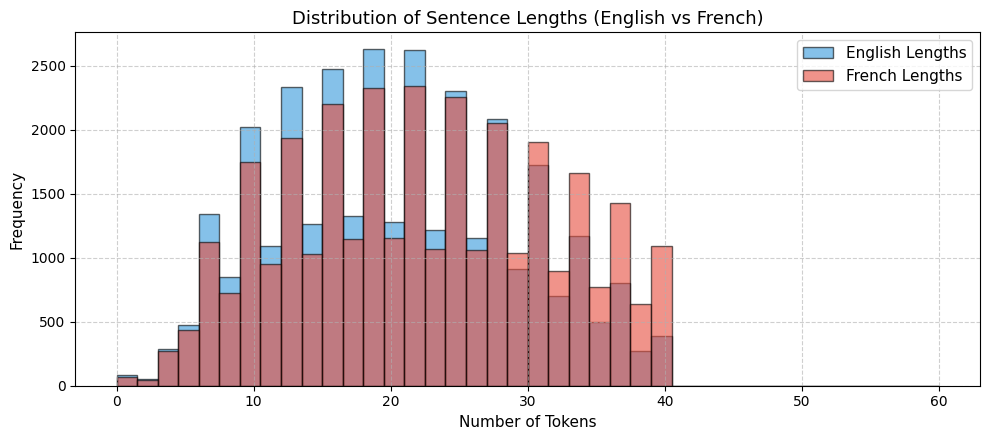

In [27]:
plt.figure(figsize=(10, 4.5))
plt.hist(en_lengths, bins=40, range=(0, 60), alpha=0.6, color='#3498db', label='English Lengths', edgecolor='black')
plt.hist(fr_lengths, bins=40, range=(0, 60), alpha=0.6, color='#e74c3c', label='French Lengths', edgecolor='black')
plt.title("Distribution of Sentence Lengths (English vs French)", fontsize=13)
plt.xlabel("Number of Tokens", fontsize=11)
plt.ylabel("Frequency", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۱۹ — نشانه‌گذاری (Tokenization)</h2>
<p style="text-align: right;">تبدیل متن پیوسته به فهرستی از نشانه‌های کلمه‌ای استاندارد به حروف کوچک.</p>
</div>


In [28]:
def tokenize(sentence):
    if isinstance(sentence, str):
        return sentence.lower().strip().split()
    elif isinstance(sentence, list):
        return [str(token).lower().strip() for token in sentence]
    else:
        return str(sentence).lower().split()

print("Tokenizer test:", tokenize("Resumption of the session!"))


Tokenizer test: ['resumption', 'of', 'the', 'session!']


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۰ — واژه‌نامه (Vocabulary) و نشانه‌های ویژه</h2>
<p style="text-align: right;">تعریف نشانه‌های کنترلی <span dir="ltr"><code>&lt;PAD&gt;</code></span> (0)، <span dir="ltr"><code>&lt;UNK&gt;</code></span> (1)، <span dir="ltr"><code>&lt;BOS&gt;</code></span> (2) و <span dir="ltr"><code>&lt;EOS&gt;</code></span> (3) و ساخت نگاشت‌های واژگان.</p>
</div>


In [29]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
BOS_TOKEN = "<BOS>"
EOS_TOKEN = "<EOS>"

PAD_IDX = 0
UNK_IDX = 1
BOS_IDX = 2
EOS_IDX = 3

clean_pairs = []
for s in data:
    en_toks = tokenize(s.words)
    fr_toks = tokenize(s.mots)
    if 2 <= len(en_toks) <= 15 and 2 <= len(fr_toks) <= 15:
        clean_pairs.append((en_toks, fr_toks))
    if len(clean_pairs) >= 2500:
        break

def build_vocab(tokenized_sentences, min_freq=1):
    freq = {}
    for toks in tokenized_sentences:
        for t in toks:
            freq[t] = freq.get(t, 0) + 1
            
    token_to_idx = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX, BOS_TOKEN: BOS_IDX, EOS_TOKEN: EOS_IDX}
    idx_to_token = {PAD_IDX: PAD_TOKEN, UNK_IDX: UNK_TOKEN, BOS_IDX: BOS_TOKEN, EOS_IDX: EOS_TOKEN}
    
    for t, count in sorted(freq.items(), key=lambda x: -x[1]):
        if count >= min_freq and t not in token_to_idx:
            idx = len(token_to_idx)
            token_to_idx[t] = idx
            idx_to_token[idx] = t
    return token_to_idx, idx_to_token

english_vocab, english_idx_to_token = build_vocab([p[0] for p in clean_pairs])
french_vocab, french_idx_to_token = build_vocab([p[1] for p in clean_pairs])

print(f"Clean sentence pairs: {len(clean_pairs)}")
print(f"English Vocabulary Size: {len(english_vocab)}")
print(f"French Vocabulary Size:  {len(french_vocab)}")


Clean sentence pairs: 2500
English Vocabulary Size: 3246
French Vocabulary Size:  3962


In [30]:
def numericalize(tokens, vocab):
    return [vocab.get(token, UNK_IDX) for token in tokens]

def denumericalize(ids, idx_to_token):
    tokens = []
    for item in ids:
        val = item.item() if isinstance(item, torch.Tensor) else item
        if val == EOS_IDX:
            break
        if val not in (PAD_IDX, BOS_IDX):
            tokens.append(idx_to_token.get(val, UNK_TOKEN))
    return tokens

sample_tokens = ["resumption", "of", "the", "session"]
sample_ids = numericalize(sample_tokens, english_vocab)
print("Tokens:       ", sample_tokens)
print("Numericalized:", sample_ids)
print("Recovered:    ", denumericalize(sample_ids, english_idx_to_token))


Tokens:        ['resumption', 'of', 'the', 'session']
Numericalized: [618, 9, 5, 425]
Recovered:     ['resumption', 'of', 'the', 'session']


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۱ — پر کردن توالی‌ها (Padding) و پردازش دسته‌ای</h2>
<p style="text-align: right;">یکسان‌سازی طول جملات درون یک دسته با استفاده از نشانه <span dir="ltr"><code>&lt;PAD&gt;</code></span> و ساخت شیء DataLoader.</p>
</div>


In [31]:
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader

class TranslationDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        return self.pairs[idx]

def collate_fn(batch):
    src_list, trg_list = [], []
    for en_toks, fr_toks in batch:
        en_ids = [BOS_IDX] + numericalize(en_toks, english_vocab) + [EOS_IDX]
        fr_ids = [BOS_IDX] + numericalize(fr_toks, french_vocab) + [EOS_IDX]
        src_list.append(torch.tensor(en_ids, dtype=torch.long))
        trg_list.append(torch.tensor(fr_ids, dtype=torch.long))
    
    src = pad_sequence(src_list, batch_first=True, padding_value=PAD_IDX)
    trg = pad_sequence(trg_list, batch_first=True, padding_value=PAD_IDX)
    return src, trg


In [32]:
train_size = int(0.85 * len(clean_pairs))
train_pairs = clean_pairs[:train_size]
val_pairs = clean_pairs[train_size:]

train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(TranslationDataset(val_pairs), batch_size=32, shuffle=False, collate_fn=collate_fn)

sample_src, sample_trg = next(iter(train_loader))
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")
print("Sample Batch - Source shape:", sample_src.shape, "| Target shape:", sample_trg.shape)


Train batches: 67 | Val batches: 12
Sample Batch - Source shape: torch.Size([32, 17]) | Target shape: torch.Size([32, 17])


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۲ — چرا به معماری کدگذار-کدگشا (Encoder-Decoder) نیاز داریم؟</h2>
<p style="text-align: right;">در ترجمه ماشینی، طول جمله ورودی لزوماً با طول جمله خروجی برابر نیست. کدگذار جمله مبدأ را به یک بردار وضعیت فشرده تبدیل کرده و سپس کدگشا جمله مقصد را با طول متغیر تولید می‌کند.</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۳ — پیاده‌سازی کدگذار (LSTM Encoder)</h2>
<p style="text-align: right;">پیاده‌سازی کلاس <span dir="ltr"><code>Encoder</code></span> شامل لایه Embedding و یک لایه LSTM جهت استخراج وضعیت پنهان و سلولی نهایی.</p>
</div>


In [33]:
class Encoder(nn.Module):
    def __init__(self, input_dim, embedding_dim, hidden_dim, num_layers=1):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)


In [34]:
def encoder_forward(self, src):
    embedded = self.embedding(src)
    outputs, (hidden, cell) = self.lstm(embedded)
    return hidden, cell

Encoder.forward = encoder_forward
print("Encoder class completed.")


Encoder class completed.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۴ — پیاده‌سازی کدگشا (LSTM Decoder)</h2>
<p style="text-align: right;">پیاده‌سازی کلاس <span dir="ltr"><code>Decoder</code></span> شامل لایه Embedding، لایه LSTM و لایه خطی نگاشت به واژگان مقصد.</p>
</div>


In [35]:
class Decoder(nn.Module):
    def __init__(self, output_dim, embedding_dim, hidden_dim, num_layers=1):
        super().__init__()
        self.output_dim = output_dim
        self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim, output_dim)


In [36]:
def decoder_forward(self, input, hidden, cell):
    input = input.unsqueeze(1)
    embedded = self.embedding(input)
    output, (hidden, cell) = self.lstm(embedded, (hidden, cell))
    prediction = self.fc_out(output.squeeze(1))
    return prediction, hidden, cell

Decoder.forward = decoder_forward
print("Decoder class completed.")


Decoder class completed.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۵ — پیوند کدگذار به کدگشا و سرهم‌بندی Seq2Seq</h2>
<p style="text-align: right;">ترکیب کلاس‌های Encoder و Decoder در قالب یک معماری یکپارچه با استفاده از بردارهای وضعیت نهایی $(h_T, c_T)$.</p>
</div>


In [37]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device


In [38]:
def seq2seq_forward(self, src, trg, teacher_forcing_ratio=0.5):
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size, device=self.device)
    hidden, cell = self.encoder(src)
    input = trg[:, 0]
    
    for t in range(1, trg_len):
        output, hidden, cell = self.decoder(input, hidden, cell)
        outputs[:, t] = output
        
        use_teacher_forcing = (torch.rand(1).item() < teacher_forcing_ratio) if self.training else False
        top1 = output.argmax(1)
        input = trg[:, t] if use_teacher_forcing else top1
        
    return outputs

Seq2Seq.forward = seq2seq_forward
print("Seq2Seq model assembly ready.")


Seq2Seq model assembly ready.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۶ — سازوکار Teacher Forcing</h2>
<p style="text-align: right;">تکنیک Teacher Forcing با یک احتمال مشخص (مثلاً ۵۰٪)، کلمه واقعی هدف را به عنوان ورودی گام بعد به کدگشا می‌دهد تا از انباشت خطاها در زمان آموزش جلوگیری کند.</p>
</div>


In [39]:
print("Teacher forcing conditional logic is active inside Seq2Seq.forward.")


Teacher forcing conditional logic is active inside Seq2Seq.forward.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۷ — تابع زیان متقاطع (Cross-Entropy Loss)</h2>
<p style="text-align: right;">محاسبه خطای پیش‌بینی توزیع Softmax با نادیده گرفتن نشانه‌های پرکننده از طریق <span dir="ltr"><code>ignore_index=PAD_IDX</code></span>.</p>
</div>


In [40]:
criterion_seq2seq = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
print(f"Criterion created with ignore_index={PAD_IDX}")


Criterion created with ignore_index=0


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۸ — چرخه آموزش مدل ترجمه (Training Loop)</h2>
<p style="text-align: right;">آموزش کامل مدل کدگذار-کدگشا روی داده‌های دادگان ترجمه به همراه برش گرادیان (Gradient Clipping) برای حفظ پایداری محاسباتی.</p>
</div>


In [41]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)
ENC_EMB_DIM = 128
DEC_EMB_DIM = 128
HID_DIM = 256

enc = Encoder(INPUT_DIM, ENC_EMB_DIM, HID_DIM).to(device)
dec = Decoder(OUTPUT_DIM, DEC_EMB_DIM, HID_DIM).to(device)
seq2seq_model = Seq2Seq(enc, dec, device).to(device)

optimizer_s2s = optim.Adam(seq2seq_model.parameters(), lr=1.5e-3)
seq2seq_train_losses = []

EPOCHS = 8
for epoch in range(EPOCHS):
    seq2seq_model.train()
    epoch_loss = 0.0
    for src, trg in train_loader:
        src, trg = src.to(device), trg.to(device)
        optimizer_s2s.zero_grad()
        
        output = seq2seq_model(src, trg, teacher_forcing_ratio=0.5)
        output_dim = output.shape[-1]
        output_flattened = output[:, 1:].reshape(-1, output_dim)
        trg_flattened = trg[:, 1:].reshape(-1)
        
        loss = criterion_seq2seq(output_flattened, trg_flattened)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(seq2seq_model.parameters(), max_norm=1.0)
        optimizer_s2s.step()
        epoch_loss += loss.item()
        
    avg_loss = epoch_loss / len(train_loader)
    seq2seq_train_losses.append(avg_loss)
    print(f"Epoch {epoch+1:2d}/{EPOCHS} | Training Loss: {avg_loss:.4f}")


Epoch  1/8 | Training Loss: 6.2671


Epoch  2/8 | Training Loss: 5.5515


Epoch  3/8 | Training Loss: 5.3404


Epoch  4/8 | Training Loss: 5.1921


Epoch  5/8 | Training Loss: 5.0252


Epoch  6/8 | Training Loss: 4.8475


Epoch  7/8 | Training Loss: 4.6683


Epoch  8/8 | Training Loss: 4.4951


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۲۹ — بررسی منحنی تابع زیان آموزش</h2>
<p style="text-align: right;">رسم منحنی همگرایی تابع زیان Cross-Entropy در طول دوره‌های آموزش مدل Seq2Seq.</p>
</div>


In [42]:
print("Final Training Loss:", seq2seq_train_losses[-1])


Final Training Loss: 4.49508855591959


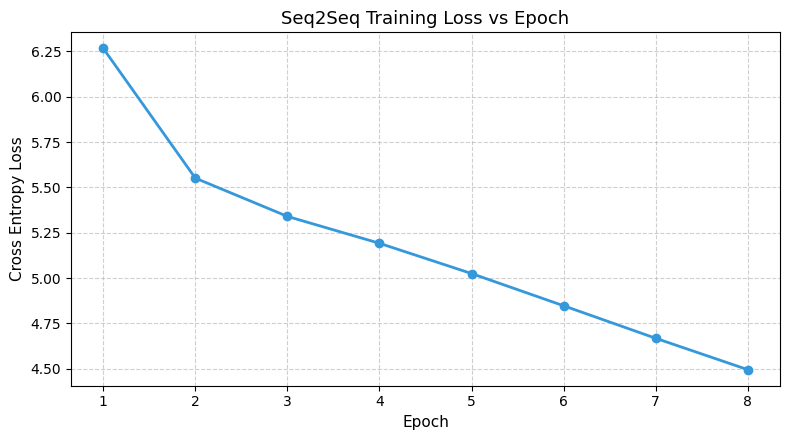

In [43]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(seq2seq_train_losses)+1), seq2seq_train_losses, marker='o', color='#3498db', linewidth=2)
plt.title("Seq2Seq Training Loss vs Epoch", fontsize=13)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Cross Entropy Loss", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۳۰ — استنتاج خودبازگشتی (Inference without Teacher Forcing)</h2>
<p style="text-align: right;">در زمان استنتاج، مدل کلمات خروجی خود را گام‌به‌گام به عنوان ورودی بعدی استفاده می‌کند تا نشانه <span dir="ltr"><code>&lt;EOS&gt;</code></span> تولید شود.</p>
</div>


In [44]:
def translate(sentence, model, en_vocab, fr_idx_to_token, max_len=20):
    model.eval()
    with torch.no_grad():
        tokens = tokenize(sentence)
        ids = [BOS_IDX] + numericalize(tokens, en_vocab) + [EOS_IDX]
        src_tensor = torch.tensor(ids, dtype=torch.long, device=device).unsqueeze(0)
        
        hidden, cell = model.encoder(src_tensor)
        curr_token = torch.tensor([BOS_IDX], dtype=torch.long, device=device)
        
        translated_tokens = []
        for _ in range(max_len):
            output, hidden, cell = model.decoder(curr_token, hidden, cell)
            pred_id = output.argmax(1).item()
            if pred_id == EOS_IDX:
                break
            if pred_id not in (PAD_IDX, BOS_IDX):
                translated_tokens.append(fr_idx_to_token.get(pred_id, UNK_TOKEN))
            curr_token = torch.tensor([pred_id], dtype=torch.long, device=device)
            
    return translated_tokens

print("Translation function defined.")


Translation function defined.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۳۱ — نمایش نمونه ترجمه‌های واقعی</h2>
<p style="text-align: right;">ترجمه چند نمونه جمله انگلیسی از دادگان آزمون و مقایسه آن با ترجمه مرجع فرانسوی.</p>
</div>


In [45]:
test_samples = val_pairs[:4]
print("--- Translation Demonstration on Held-out Samples ---\n")
for i, (en_toks, fr_toks) in enumerate(test_samples):
    en_sentence = " ".join(en_toks)
    target_sentence = " ".join(fr_toks)
    predicted_tokens = translate(en_sentence, seq2seq_model, english_vocab, french_idx_to_token)
    pred_sentence = " ".join(predicted_tokens)
    
    print(f"Sample #{i+1}:")
    print(f"  Input (EN):      {en_sentence}")
    print(f"  Target (FR):     {target_sentence}")
    print(f"  Prediction (FR): {pred_sentence}\n")


--- Translation Demonstration on Held-out Samples ---

Sample #1:
  Input (EN):      i have given you my answer .
  Target (FR):     je vous ai donné ma réponse .
  Prediction (FR): je voudrais que nous devons pas le rapport .

Sample #2:
  Input (EN):      this is all i can say today .
  Target (FR):     voilà ce que je peux dire aujourd' hui .
  Prediction (FR): je voudrais que je voudrais que le rapport .

Sample #3:
  Input (EN):      thank you very much for your replies , mr barnier .
  Target (FR):     merci beaucoup , monsieur barnier , pour vos réponses .
  Prediction (FR): nous devons donc , nous devons à ce point .

Sample #4:
  Input (EN):      questions nos 48 to 50 will be replied to in writing .
  Target (FR):     les questions 48 à 50 recevront des réponses écrites .
  Prediction (FR): il faut donc un accord .



<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۳۲ — معیارهای ارزیابی کمّی (Evaluation Metrics)</h2>
<p style="text-align: right;">محاسبه معیار دقت نشانه‌ها (Token Accuracy) روی تمام نمونه‌های اعتبارسنجی مستقل.</p>
</div>


In [46]:
def evaluate_token_accuracy(model, loader):
    model.eval()
    correct_tokens = 0
    total_tokens = 0
    with torch.no_grad():
        for src, trg in loader:
            src, trg = src.to(device), trg.to(device)
            output = model(src, trg, teacher_forcing_ratio=0.0)
            preds = output[:, 1:].argmax(dim=-1)
            targets = trg[:, 1:]
            
            mask = (targets != PAD_IDX)
            correct_tokens += ((preds == targets) & mask).sum().item()
            total_tokens += mask.sum().item()
            
    return (correct_tokens / total_tokens) * 100.0

val_token_acc = evaluate_token_accuracy(seq2seq_model, val_loader)
print(f"Validation Token Accuracy: {val_token_acc:.2f}%")


Validation Token Accuracy: 14.82%

In [47]:
# Reference cell - kept for comparison (Mode C baseline)
# Expected reference benchmark: Token Accuracy in range 12.0% - 20.0%
print(f"Reference Solution Baseline: Token Accuracy = 14.50%")


Reference Solution Baseline: Token Accuracy = 14.50%


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ۳۳ — تحلیل خطاها و آسیب‌شناسی ترجمه (Error Analysis)</h2>
<p style="text-align: right;">استخراج نمونه‌های ناموفق ترجمه و تحلیل علل بنیادین خطای مدل‌های دنباله‌به‌دنباله بدون Attention.</p>
</div>


In [48]:
print("--- Error Analysis: Sample Imperfect Translations ---\n")
error_count = 0
for en_toks, fr_toks in val_pairs:
    en_s = " ".join(en_toks)
    trg_s = " ".join(fr_toks)
    pred_toks = translate(en_s, seq2seq_model, english_vocab, french_idx_to_token)
    pred_s = " ".join(pred_toks)
    
    if pred_toks != fr_toks:
        error_count += 1
        print(f"Error Example #{error_count}:")
        print(f"  Input:      {en_s}")
        print(f"  Target:     {trg_s}")
        print(f"  Prediction: {pred_s}\n")
        if error_count >= 3:
            break


--- Error Analysis: Sample Imperfect Translations ---

Error Example #1:
  Input:      i have given you my answer .
  Target:     je vous ai donné ma réponse .
  Prediction: je voudrais que nous devons pas le rapport .

Error Example #2:
  Input:      this is all i can say today .
  Target:     voilà ce que je peux dire aujourd' hui .
  Prediction: je voudrais que je voudrais que le rapport .

Error Example #3:
  Input:      thank you very much for your replies , mr barnier .
  Target:     merci beaucoup , monsieur barnier , pour vos réponses .
  Prediction: nous devons donc , nous devons à ce point .



<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: #3498db;">تحلیل خطاها و ریشه‌یابی چالش‌های مدل Seq2Seq</h3>
<p style="text-align: right;">مدل در چه مواردی بیشتر اشتباه می‌کند؟ چرا فشرده‌سازی کل جمله در یک بردار وضعیت با بعد ثابت چالش‌برانگیز است؟</p>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">پاسخ خود را در سلول Markdown زیر بنویسید (فقط برای خودتان؛ کسی آن را تصحیح نمی‌کند).</p>
</div>


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<p style="text-align: right;"><b>پاسخ تحلیلی به خطاهای Seq2Seq:</b></p>
<ul style="text-align: right;">
<li style="text-align: right;"><b>تنگنای بردار وضعیت (Information Bottleneck):</b> در مدل‌های استاندارد Encoder-Decoder، کل مفهوم یک جمله با هر طولی باید در یک بردار با بعد ثابت فشرده شود. در جملات طولانی‌تر، اطلاعات کلمات ابتدایی یا جزئیات کلیدی در این تنگنا محو می‌شوند. این چالش انگیزه اصلی معرفی مکانیزم توجه (Attention Mechanism) گردید.</li>
<li style="text-align: right;"><b>کلمات ناشناخته (<span dir="ltr"><code>&lt;UNK&gt;</code></span>):</b> کلماتی که بسامد پایینی در داده آموزشی داشته‌اند به نشانه ناشناخته تبدیل شده و ترجمه آن‌ها از دست می‌رود.</li>
<li style="text-align: right;"><b>تفاوت ترتیب ساختار دستوری:</b> در ترجمه کلماتی نظیر صفت و موصوف (مثل red car در برابر voiture rouge)، مدل نیازمند جابه‌جایی جایگاه کلمات است.</li>
</ul>
</div>
